# Baselines: Random & Popularity + Evaluation Harness

**Objective.** Lock in the evaluation harness (Recall@20, NDCG@10, Catalog
Coverage) that every later stage reuses unchanged, and put the two required
floor baselines on the board: Random and Popularity. Every retrieval and
ranking model from notebook 03 onward is judged against these numbers. If
MF-BPR cannot beat Popularity, something is wrong before we even reach the
two-tower.

**Depends on notebook 01** (`full-recsys-data-prep-explore`). This notebook
consumes its four Parquet outputs and does no data prep of its own. Attach
notebook 01 as an input so its `data/processed/` folder is available under
`/kaggle/input/`:

> Settings (right panel) > Add Input > Notebook Output > select your run of
> `full-recsys-data-prep-explore`.

The loader in Section 1 auto-detects that folder wherever Kaggle mounts it, so
the exact dataset slug does not matter.

**What notebook 01 hands us.** Four Parquet files with a `label` column where
**every interaction is a positive** (`label == 1`). Notebook 01 defines
relevance as any interaction with a book, not a star-rating threshold, so the
ground truth for Recall/NDCG is simply the set of items a user touched in the
evaluation split.

**Self-contained.** No external code dependency. The harness and both
recommenders are defined inline in Section 2 so later notebooks copy them
forward unchanged.

## 1. Setup and input resolution

The one non-trivial part of setup on Kaggle is finding the data. When you
attach a notebook's output as an input, Kaggle mounts it under a slug-based
path you do not control (`/kaggle/input/<something>/data/processed/...`).
Rather than hardcode a guessed path, we scan for the `processed` folder that
actually contains all four Parquet files and use the first match. The same
resolver also handles a local Colab or laptop run, so the notebook is portable
without edits.

Outputs go to `/kaggle/working/`, which Kaggle automatically saves as this
notebook's output (metrics and Parquet artifacts, written in Section 9).

In [1]:
import os
import sys
from pathlib import Path

REQUIRED_FILES = ("train.parquet", "val.parquet", "test.parquet", "items_meta.parquet")


def resolve_input_dir():
    # Candidate roots, in priority order: an attached notebook output on Kaggle,
    # a local data-prep run, or a previous run in the Kaggle working dir.
    search_roots = [Path("/kaggle/input"), Path("data"), Path("/kaggle/working/data"), Path(".")]
    for root in search_roots:
        if not root.exists():
            continue
        # A "processed" (or "processed_sample") dir holding all four files wins.
        for processed in sorted(root.rglob("processed*")):
            if processed.is_dir() and all((processed / f).exists() for f in REQUIRED_FILES):
                return processed
    raise FileNotFoundError(
        "Could not find the four processed Parquet files. On Kaggle: Settings > "
        "Add Input > Notebook Output > your run of 'full-recsys-data-prep-explore'. "
        f"Looked for {REQUIRED_FILES} under {[str(r) for r in search_roots]}."
    )


INPUT_DIR = resolve_input_dir()

# Everything written under /kaggle/working is saved as this notebook's output.
REPO_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
RESULTS_PATH = REPO_ROOT / "results" / "metrics.csv"
BASELINE_OUT_DIR = REPO_ROOT / "data" / "baselines"

print("Reading splits from:", INPUT_DIR)
print("Metrics ->", RESULTS_PATH)
print("Parquet artifacts ->", BASELINE_OUT_DIR)

Reading splits from: /kaggle/input/notebooks/goodoldies/full-recsys-data-prep-explore/data/processed
Metrics -> /kaggle/working/results/metrics.csv
Parquet artifacts -> /kaggle/working/data/baselines


In [2]:
from typing import Dict, Iterable, List, Sequence, Set

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Evaluation harness and baseline recommenders

Defined inline, not imported, so this notebook has zero dependency on any file
outside itself. These exact functions are reused unchanged by every later
notebook (03 to 05), just copied forward, so every stage is scored the same way
and results stay comparable.

The three metrics, all computed on each user's ranked top-K list:

**Recall@K** answers "of everything this user liked in the split, how much did
we surface?" It counts hits in the top-K over the user's total positives, then
averages over users. Order inside the list does not matter.

**NDCG@10** answers "are the good items near the top?" It discounts each hit by
its position (`1 / log2(rank + 1)`) and normalizes by the ideal ordering, so
ranking a positive at rank 1 beats ranking it at rank 10. This is the ordering
signal Recall ignores.

**Catalog Coverage** answers "how much of the catalog does the model ever
recommend?" It catches a model that scores fine on accuracy by handing everyone
the same few bestsellers. It is a diversity signal, not simply higher-is-better.

Two recommenders. **Random** draws uniform items per user (the accuracy floor,
coverage ceiling). **Popularity** gives everyone the same globally-ranked list
minus their own history (strong accuracy, near-zero coverage). The gap between
Popularity's accuracy and its coverage is exactly what personalized retrieval
must close later.

In [3]:
CATEGORICAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=CATEGORICAL), "font.family": "sans-serif", "figure.dpi": 110,
})


def build_user_positive_sets(df, user_col="user_id", item_col="parent_asin", label_col="label"):
    """Ground truth for evaluation: items each user positively interacted with in a split."""
    pos = df[df[label_col] == 1]
    return pos.groupby(user_col)[item_col].apply(set).to_dict()


def build_user_history(df, user_col="user_id", item_col="parent_asin"):
    """Items a user has already interacted with (any label) - excluded from their recommendations."""
    return df.groupby(user_col)[item_col].apply(set).to_dict()


def recall_at_k(recs, ground_truth, k):
    scores = []
    for u, gt in ground_truth.items():
        if not gt:
            continue
        hits = len(set(recs.get(u, [])[:k]) & gt)
        scores.append(hits / len(gt))
    return float(np.mean(scores)) if scores else 0.0


def ndcg_at_k(recs, ground_truth, k):
    scores = []
    for u, gt in ground_truth.items():
        if not gt:
            continue
        topk = recs.get(u, [])[:k]
        # enumerate starts at 0, so position i in the formula (from 1) is log2(i + 2) here.
        dcg = sum(1.0 / np.log2(i + 2) for i, it in enumerate(topk) if it in gt)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(gt), k)))
        scores.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def catalog_coverage(recs, catalog):
    catalog = set(catalog)
    if not catalog:
        return 0.0
    recommended = set()
    for items in recs.values():
        recommended.update(items)
    return len(recommended & catalog) / len(catalog)


def evaluate(recs, ground_truth, catalog, recall_ks=(20,), ndcg_ks=(10,)):
    out = {}
    for k in recall_ks:
        out[f"recall@{k}"] = recall_at_k(recs, ground_truth, k)
    for k in ndcg_ks:
        out[f"ndcg@{k}"] = ndcg_at_k(recs, ground_truth, k)
    out["catalog_coverage"] = catalog_coverage(recs, catalog)
    return out


def log_result(results_path, stage, model, split, metrics, notes=""):
    """Append/upsert one row into the running results ledger (keyed by stage+model+split)."""
    results_path = Path(results_path)
    row = {"stage": stage, "model": model, "split": split, **metrics, "notes": notes}
    if results_path.exists():
        df = pd.read_csv(results_path)
        df = df[~((df["stage"] == stage) & (df["model"] == model) & (df["split"] == split))]
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        results_path.parent.mkdir(parents=True, exist_ok=True)
        df = pd.DataFrame([row])
    df.to_csv(results_path, index=False)
    return df


class RandomRecommender:
    """Uniform-random item recommendations, excluding each user's train history."""

    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)
        self.catalog = None

    def fit(self, train_df, item_col="parent_asin"):
        self.catalog = train_df[item_col].unique()
        return self

    def recommend(self, user_ids, history, k=20, oversample=3):
        # Rejection sampling instead of np.random.choice(replace=False) per user:
        # the catalog is large and a user's history tiny, so oversampling and
        # filtering is far cheaper than a full permutation per user.
        recs = {}
        n_catalog = len(self.catalog)
        for u in user_ids:
            seen = history.get(u, set())
            chosen, chosen_set = [], set()
            while len(chosen) < k:
                idx = self.rng.integers(0, n_catalog, size=(k - len(chosen)) * oversample)
                for it in self.catalog[idx]:
                    if it not in seen and it not in chosen_set:
                        chosen.append(it)
                        chosen_set.add(it)
                        if len(chosen) == k:
                            break
            recs[u] = chosen
        return recs


class PopularityRecommender:
    """Same globally-ranked-by-popularity list for every user, minus their own history."""

    def __init__(self):
        self.ranked_items = None
        self.item_counts = None

    def fit(self, train_df, item_col="parent_asin", label_col="label", use_positive_only=True):
        # Popularity = count of positive interactions. Under notebook 01's
        # "any interaction is positive" definition every train row has label==1,
        # so this equals the raw interaction count. Keeping the positive filter
        # keeps the code correct if a later data-prep run reintroduces a rating
        # threshold (label 0/1).
        counts_df = train_df[train_df[label_col] == 1] if use_positive_only else train_df
        self.item_counts = counts_df[item_col].value_counts()
        self.ranked_items = self.item_counts.index.to_numpy()
        return self

    def recommend(self, user_ids, history, k=20, buffer=200):
        recs = {}
        top_pool = self.ranked_items[: k + buffer]
        for u in user_ids:
            seen = history.get(u, set())
            chosen = [it for it in top_pool if it not in seen][:k]
            if len(chosen) < k:
                # Very active user exhausted the pool - fall back to the full ranked list.
                chosen = [it for it in self.ranked_items if it not in seen][:k]
            recs[u] = chosen
        return recs

## 3. Load the splits produced by notebook 01

Four Parquet files. The train catalog (unique train items) is the universe
Catalog Coverage is measured against. We only recommend and score items that
exist in train, which matches notebook 01's warm-start split where val/test are
already restricted to train users and items.

In [4]:
train = pd.read_parquet(INPUT_DIR / "train.parquet")
val = pd.read_parquet(INPUT_DIR / "val.parquet")
test = pd.read_parquet(INPUT_DIR / "test.parquet")
items_meta = pd.read_parquet(INPUT_DIR / "items_meta.parquet")

catalog = set(train["parent_asin"].unique())
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  catalog={len(catalog):,} items")
train.head()

train=592,954  val=18,656  test=10,234  catalog=40,366 items


,user_id,parent_asin,rating,timestamp,verified_purchase,label
0,AEWRMMBDOWIBM6D646AF5KA5XT4Q,173298512X,4.0,2020-07-25 04:22:45.475,False,1
1,AEHCDOGGXKCL2FTKSXXWXOF2KX7Q,0525518355,5.0,2020-07-25 04:26:21.716,False,1
2,AH4Z5TTHYSGZW5VSY7XNL2DD2OIQ,1250773660,4.0,2020-07-25 04:32:37.001,False,1
3,AGLKSINF2JUMVI3REZKESFXO2GHQ,0140177396,1.0,2020-07-25 04:32:59.094,True,1
4,AGLKSINF2JUMVI3REZKESFXO2GHQ,1416912053,4.0,2020-07-25 04:35:03.054,True,1


## 4. Build the evaluation inputs

**History** (from train): items to exclude from a user's recommendations. We
never re-recommend something they already interacted with, since surfacing a
known item is trivial and useless.

**Ground truth** (from val/test): a user's positive items in that split. Under
notebook 01's definition every interaction is positive, so this is every item
the user touched in the split. Users with zero rows in a split contribute no
Recall/NDCG signal and are dropped from the average. There is nothing a ranked
list could get right for them, so including them would only add zeros and
distort the score.

In [5]:
train_history = build_user_history(train)
val_ground_truth = build_user_positive_sets(val)
test_ground_truth = build_user_positive_sets(test)

print(f"val users with >=1 positive: {len(val_ground_truth):,} / {val['user_id'].nunique():,}")
print(f"test users with >=1 positive: {len(test_ground_truth):,} / {test['user_id'].nunique():,}")

val users with >=1 positive: 10,179 / 10,179
test users with >=1 positive: 6,096 / 6,096


## 5. Evaluation harness

All three metrics are computed against a user's ranked top-K recommendation
list, using the functions from Section 2 that every later notebook reuses
unchanged.

We evaluate on both val and test even though these baselines have no
hyperparameters to tune. Later notebooks reuse this exact cell structure and do
need val for tuning, so keeping the harness identical from the start avoids
subtle divergence bugs later. The test row is the one that goes into the final
comparison table.

## 6. Random baseline

Fit stores the train catalog. Recommend draws 20 uniform-random items per user,
skipping their history. This is the accuracy floor: if a real model cannot beat
random, the model or the evaluation is broken.

In [6]:
random_model = RandomRecommender(seed=42).fit(train)

val_users = list(val_ground_truth.keys())
test_users = list(test_ground_truth.keys())

random_val_recs = random_model.recommend(val_users, train_history, k=20)
random_test_recs = random_model.recommend(test_users, train_history, k=20)

random_val_metrics = evaluate(random_val_recs, val_ground_truth, catalog)
random_test_metrics = evaluate(random_test_recs, test_ground_truth, catalog)

print("Random  | val: ", random_val_metrics)
print("Random  | test:", random_test_metrics)

Random  | val:  {'recall@20': 0.0006208315595288775, 'ndcg@10': 9.873229301524197e-05, 'catalog_coverage': 0.9936580290343359}
Random  | test: {'recall@20': 0.0006430085662369126, 'ndcg@10': 0.00015861778525326929, 'catalog_coverage': 0.9509488183124412}


**Interpretation.** With a catalog this large, Recall@20 and NDCG@10 should be
very close to zero. The odds of 20 uniform-random draws landing on a user's
handful of positives out of hundreds of thousands of items are negligible.
Catalog Coverage, on the other hand, should be near 100%: random recommending
spreads across the whole catalog by construction. This is the baseline's whole
point, a floor for accuracy and a ceiling for coverage. Every real model should
beat it on accuracy while giving up some coverage.

## 7. Popularity baseline

Fit counts interactions per item and ranks items most-popular-first. Recommend
gives every user the same ranked list minus their own history. This is the
non-personalized reference that personalized models actually have to beat.

In [7]:
popularity_model = PopularityRecommender().fit(train)

popularity_val_recs = popularity_model.recommend(val_users, train_history, k=20)
popularity_test_recs = popularity_model.recommend(test_users, train_history, k=20)

popularity_val_metrics = evaluate(popularity_val_recs, val_ground_truth, catalog)
popularity_test_metrics = evaluate(popularity_test_recs, test_ground_truth, catalog)

print("Popularity | val: ", popularity_val_metrics)
print("Popularity | test:", popularity_test_metrics)

Popularity | val:  {'recall@20': 0.009566142669590947, 'ndcg@10': 0.0031838465651950654, 'catalog_coverage': 0.0007927463707080216}
Popularity | test: {'recall@20': 0.007971389393633488, 'ndcg@10': 0.0020985354013348012, 'catalog_coverage': 0.0007927463707080216}


**Interpretation.** Popularity should clear Random by a wide margin on
Recall@20 and NDCG@10. Bestsellers are, by definition, disproportionately
likely to be in many users' positive sets. But watch Catalog Coverage:
Popularity recommends the same handful of top items to nearly everyone, so
coverage should be extremely low (often under 1%) despite decent accuracy. That
accuracy-up, coverage-down tradeoff is exactly the gap MF-BPR and the two-tower
are meant to close in notebooks 03 and 04. Personalized retrieval should reach
Popularity-or-better accuracy while covering far more of the catalog.

## 8. Compare and visualize

Assemble the four metric rows (Random and Popularity, val and test) into one table, then plot the test metrics.

We use two panels rather than one bar chart. Recall@20 and NDCG@10 sit near zero while Catalog Coverage runs on a 0-to-1 scale, so putting them on a shared axis makes the tall coverage bar swallow the accuracy bars and hides the very comparison we care about (Popularity beats Random on accuracy). Splitting accuracy from coverage, each on its own axis, keeps both the accuracy win and the accuracy-versus-coverage tradeoff readable.

In [8]:
comparison = pd.DataFrame({
    "Random (val)": random_val_metrics,
    "Random (test)": random_test_metrics,
    "Popularity (val)": popularity_val_metrics,
    "Popularity (test)": popularity_test_metrics,
}).T
comparison

,recall@20,ndcg@10,catalog_coverage
Random (val),0.000621,0.000099,0.993658
Random (test),0.000643,0.000159,0.950949
Popularity (val),0.009566,0.003184,0.000793
Popularity (test),0.007971,0.002099,0.000793


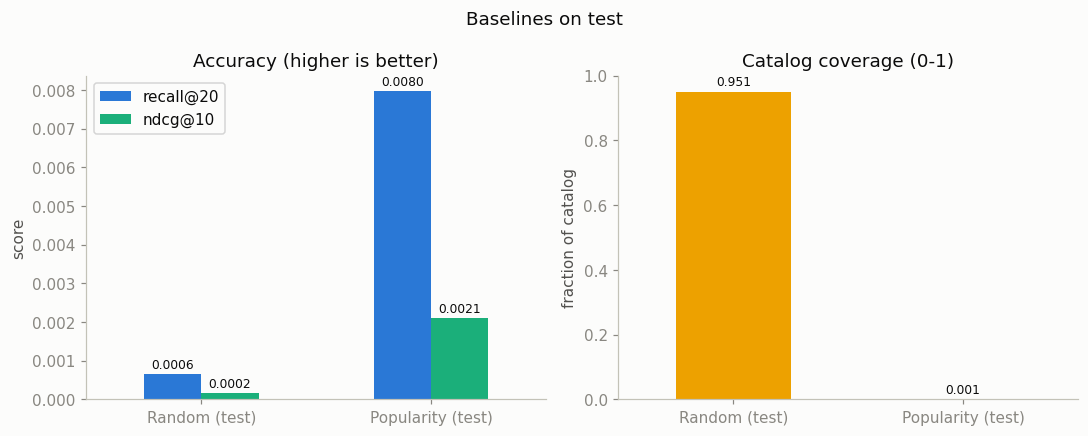

In [9]:
# Two panels because the metrics live on different scales: Recall@20/NDCG@10 are
# near zero while Catalog Coverage runs 0-1. On a single axis coverage's bar
# swallows the accuracy bars and hides the Popularity-vs-Random gap entirely, so
# we split accuracy (left) from coverage (right), each with its own y-axis.
rows = ["Random (test)", "Popularity (test)"]
acc = comparison.loc[rows, ["recall@20", "ndcg@10"]]
cov = comparison.loc[rows, ["catalog_coverage"]]

fig, (ax_acc, ax_cov) = plt.subplots(1, 2, figsize=(10, 4))

acc.plot(kind="bar", ax=ax_acc, color=CATEGORICAL[:2])
ax_acc.set_title("Accuracy (higher is better)")
ax_acc.set_ylabel("score")
ax_acc.legend(loc="upper left")
for c in ax_acc.containers:
    ax_acc.bar_label(c, fmt="%.4f", padding=2, fontsize=8)

cov.plot(kind="bar", ax=ax_cov, color=[CATEGORICAL[2]], legend=False)
ax_cov.set_title("Catalog coverage (0-1)")
ax_cov.set_ylabel("fraction of catalog")
ax_cov.set_ylim(0, 1)
for c in ax_cov.containers:
    ax_cov.bar_label(c, fmt="%.3f", padding=2, fontsize=8)

for ax in (ax_acc, ax_cov):
    ax.set_xticklabels(rows, rotation=0)
    ax.grid(False)

fig.suptitle("Baselines on test")
plt.tight_layout()
plt.show()

## 9. Save artifacts (metrics and Parquet)

Three things get written to `/kaggle/working/`, which Kaggle saves as this
notebook's output so notebooks 03 to 05 and the webapp can attach it:

1. **`results/metrics.csv`** - the running ledger, upserted by `log_result`.
   Single source of truth for the final comparison table in `ANALYSIS.md`.
   Keyed by (stage, model, split), so re-running overwrites rows instead of
   duplicating them.
2. **`data/baselines/popularity_ranking.parquet`** - the fitted Popularity
   model as data: every item with its interaction count and rank. Directly
   reusable as the webapp's logged-out "trending" row and as a candidate source
   for the multi-source retrieval bonus, without re-fitting.
3. **`data/baselines/baseline_test_recommendations.parquet`** - the top-20
   Random and Popularity lists per test user, in long form. Handy for the
   ablation and cold-start analysis and for blending baselines with later
   retrievers.

In [10]:
def recs_to_long_df(recs, model, split):
    rows = []
    for u, items in recs.items():
        for rank, item in enumerate(items, start=1):
            rows.append((model, split, u, rank, item))
    return pd.DataFrame(rows, columns=["model", "split", "user_id", "rank", "parent_asin"])


# 1. Metrics ledger.
log_result(RESULTS_PATH, "baseline", "Random", "val", random_val_metrics)
log_result(RESULTS_PATH, "baseline", "Random", "test", random_test_metrics)
log_result(RESULTS_PATH, "baseline", "Popularity", "val", popularity_val_metrics)
log_result(RESULTS_PATH, "baseline", "Popularity", "test", popularity_test_metrics)

# 2. Fitted popularity model as a reusable artifact.
BASELINE_OUT_DIR.mkdir(parents=True, exist_ok=True)
popularity_ranking = (
    popularity_model.item_counts.rename_axis("parent_asin")
    .reset_index(name="interaction_count")
)
popularity_ranking["rank"] = np.arange(1, len(popularity_ranking) + 1)
popularity_ranking.to_parquet(BASELINE_OUT_DIR / "popularity_ranking.parquet", index=False)

# 3. Top-20 baseline recommendations per test user (long form).
baseline_recs = pd.concat([
    recs_to_long_df(random_test_recs, "Random", "test"),
    recs_to_long_df(popularity_test_recs, "Popularity", "test"),
], ignore_index=True)
baseline_recs.to_parquet(BASELINE_OUT_DIR / "baseline_test_recommendations.parquet", index=False)

print("Metrics ->", RESULTS_PATH)
print("Popularity ranking ->", BASELINE_OUT_DIR / "popularity_ranking.parquet", f"({len(popularity_ranking):,} items)")
print("Baseline recs ->", BASELINE_OUT_DIR / "baseline_test_recommendations.parquet", f"({len(baseline_recs):,} rows)")
pd.read_csv(RESULTS_PATH)

Metrics -> /kaggle/working/results/metrics.csv
Popularity ranking -> /kaggle/working/data/baselines/popularity_ranking.parquet (40,366 items)
Baseline recs -> /kaggle/working/data/baselines/baseline_test_recommendations.parquet (243,840 rows)


,stage,model,split,recall@20,ndcg@10,catalog_coverage,notes
0,baseline,Random,val,0.000621,0.000099,0.993658,NaN
1,baseline,Random,test,0.000643,0.000159,0.950949,NaN
2,baseline,Popularity,val,0.009566,0.003184,0.000793,NaN
3,baseline,Popularity,test,0.007971,0.002099,0.000793,NaN


## 10. Save the fitted models

The Parquet files in Section 9 hold *outputs* (rankings and recommendation
lists). Here we save the fitted **model objects** themselves, so the webapp can
reload a model and call `.recommend(...)` live instead of reading a precomputed
table.

We use `pickle`, Python's standard object-serialization format. It captures the
model's learned state exactly: the Random model's catalog and seed, the
Popularity model's ranked item list and counts. This mirrors how the later
notebooks export their trained models (PyTorch `.pt` weights for MF-BPR and the
two-tower).

One caveat worth knowing for the webapp: to unpickle these, the
`RandomRecommender` / `PopularityRecommender` class definitions must be
importable in that process (copy the two classes into a shared module). If you
want a class-independent artifact instead, `popularity_ranking.parquet` from
Section 9 already contains everything the Popularity model knows, and can be
loaded as a plain table with no code dependency.

In [11]:
import pickle

MODELS_DIR = REPO_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

with open(MODELS_DIR / "random_recommender.pkl", "wb") as f:
    pickle.dump(random_model, f)
with open(MODELS_DIR / "popularity_recommender.pkl", "wb") as f:
    pickle.dump(popularity_model, f)

# Round-trip check: reload and confirm the model still recommends, since the
# webapp will unpickle these exact files at startup.
with open(MODELS_DIR / "popularity_recommender.pkl", "rb") as f:
    reloaded = pickle.load(f)
sample_recs = reloaded.recommend(test_users[:1], train_history, k=5)
assert len(next(iter(sample_recs.values()))) == 5

print("Saved models to", MODELS_DIR)
for p in sorted(MODELS_DIR.glob("*.pkl")):
    print(" ", p.name, f"{p.stat().st_size/1024:.1f} KB")

Saved models to /kaggle/working/models
  popularity_recommender.pkl 1025.3 KB
  random_recommender.pkl 513.2 KB


## Summary

- Evaluation harness (Section 2): Recall@20, NDCG@10, Catalog Coverage, reused
  unchanged by every later notebook so all stages are comparable.
- Random: accuracy floor, coverage ceiling.
- Popularity: much stronger accuracy, very low coverage. The tradeoff
  personalized retrieval needs to beat.
- Outputs saved to `/kaggle/working/`: `results/metrics.csv` (final comparison
  table), `data/baselines/popularity_ranking.parquet` (reusable trending list),
  and `data/baselines/baseline_test_recommendations.parquet` (per-user lists for
  analysis and blending).
- Compliance: time-based split inherited from notebook 01, no full-pipeline
  libraries (plain NumPy and pandas only), all three mandatory metrics reported,
  markdown narration with an interpretation cell after each result.